# Part 3.1: Smart School Desk CNN — Colab & Dataset Guide

**Thông tin sinh viên:**
- **Họ và tên:** Trần Võ Bá Vương
- **MSSV:** 24020008
- **Lớp / Học phần:** AI Assignment 3 — Smart School Desk CNN
- **Ngày:** 24/09/2026  
- **Mục tiêu:** Xây dựng CNN phân loại 6 đồ dùng học tập từ ảnh.

Notebook này hướng dẫn tải công cụ tạo dataset, kiểm tra nguồn/giấy phép, huấn luyện CNN và đánh giá trên ảnh thật chưa dùng khi huấn luyện. Chạy lần lượt từ trên xuống trong Google Colab. Chọn **Runtime → Change runtime type → T4 GPU** nếu có; GPU là tùy chọn.

> ZIP được chia sẻ là **công cụ tạo dataset**, không phải bộ ảnh đã có sẵn. Công cụ tìm ảnh trên Wikimedia Commons và chỉ chấp nhận metadata giấy phép CC BY, CC BY-SA, CC0 hoặc Public Domain. Kết quả phụ thuộc vào mạng và số ảnh tìm được.


## 1. Learning goals và lưu ý dữ liệu

Sau bài này, bạn có thể chuẩn bị dữ liệu ảnh có metadata, tạo train/validation/test không rò rỉ ảnh gốc, xây dựng CNN bằng TensorFlow/Keras, và đọc các chỉ số phân loại.

Sáu nhãn: `pen`, `pencil`, `eraser`, `ruler`, `scissors`, `notebook`. Cấu hình starter mặc định tối đa 5 ảnh thật/lớp và 20 ảnh biến đổi/ảnh thật. Dataset nhỏ này chỉ dùng để học quy trình; augmentation không tạo thêm bối cảnh hoặc vật thể thực sự mới, do đó không thay thế việc tự chụp thêm ảnh đa dạng. Kết quả test từ một ảnh/lớp cũng rất không ổn định và không đại diện cho hiệu năng triển khai.

In [ ]:
import os
import random
import re
import sys
import json
import zipfile
import subprocess
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
CLASSES = ['pen', 'pencil', 'eraser', 'ruler', 'scissors', 'notebook']
IMAGE_SIZE = (128, 128)
BATCH_SIZE = 32
DATA_ROOT = Path('/content/school_supplies_data')
print('Python:', sys.version.split()[0])
print('GPU devices:', end=' ')
try:
    import tensorflow as tf
    print(tf.config.list_physical_devices('GPU'))
except ImportError:
    print('TensorFlow will be installed in the next cell.')

Python: 3.13.18
GPU devices: []


## 2. Cài đặt thư viện

Colab thường đã cài TensorFlow. Cell này chỉ cài/bổ sung các thư viện dùng trong notebook.

In [ ]:
%pip -q install requests Pillow scikit-learn tensorflow pandas matplotlib

## 3. Tải và giải nén công cụ dataset

Notebook thử tải ZIP từ Google Drive. Nếu Drive không trả về ZIP trực tiếp, hãy tải ZIP bằng trình duyệt rồi dùng nút upload dự phòng. Không chia sẻ lại ảnh nếu chưa tuân thủ điều kiện attribution trong `metadata.csv`.

In [ ]:
ZIP_PATH = Path('/content/School_Supplies_Dataset_Tool.zip')
DRIVE_URL = 'https://drive.google.com/uc?export=download&id=13JVX0vEKHsyoZV4SJDiNoZsjAIZkIjUt'

if not ZIP_PATH.exists():
    try:
        import requests
        response = requests.get(DRIVE_URL, timeout=60)
        response.raise_for_status()
        ZIP_PATH.write_bytes(response.content)
        if not zipfile.is_zipfile(ZIP_PATH):
            ZIP_PATH.unlink(missing_ok=True)
            raise RuntimeError('Google Drive response was not a ZIP archive.')
    except Exception as download_error:
        print(f'Download failed: {download_error}')
        print('Upload the ZIP you downloaded from Google Drive.')
        from google.colab import files
        uploaded = files.upload()
        if not uploaded:
            raise RuntimeError('No ZIP file was uploaded.')
        uploaded_name = next(iter(uploaded))
        ZIP_PATH = Path('/content') / uploaded_name

if not zipfile.is_zipfile(ZIP_PATH):
    raise ValueError(f'{ZIP_PATH} is not a valid ZIP. Download/upload the shared dataset-tool archive.')

TOOL_DIR = Path('/content/school_supplies_crawler_tool')
with zipfile.ZipFile(ZIP_PATH) as archive:
    archive.extractall('/content')
SCRIPT_PATH = TOOL_DIR / 'school_supplies_dataset_tool.py'
README_PATH = TOOL_DIR / 'README.md'
if not SCRIPT_PATH.exists() or not README_PATH.exists():
    raise FileNotFoundError('Expected scraper script/README not found; check that the correct ZIP was uploaded.')
print('Tool files:', [p.name for p in TOOL_DIR.iterdir()])
print(README_PATH.read_text(encoding='utf-8')[:2000])

Tool files: ['README.md', 'school_supplies_dataset_tool.py', 'School_Supplies_Dataset_Tool_Colab.ipynb', 'requirements.txt']
# School Supplies Dataset Tool

Tool này dùng để:

1. Tải một số **ảnh thật** của 6 lớp đồ dùng học tập từ Wikimedia Commons.
2. Chỉ giữ ảnh có metadata giấy phép rõ ràng như CC BY, CC BY-SA, CC0 hoặc Public Domain.
3. Lưu `metadata.csv` để sinh viên xem nguồn, tác giả và giấy phép.
4. Sinh thêm ảnh augmented từ ảnh thật để dùng làm starter dataset.

## Classes

- pen
- pencil
- eraser
- ruler
- scissors
- notebook

## Run on Google Colab

```python
!pip install -r requirements.txt
!python school_supplies_dataset_tool.py     --output /content/school_supplies_data     --real-per-class 5     --aug-per-real 20     --size 256
```

Kết quả:

```text
school_supplies_data/
├── real_samples/
│   ├── pen/
│   ├── pencil/
│   ├── eraser/
│   ├── ruler/
│   ├── scissors/
│   └── notebook/
├── augmented/
│   └── ...
└── metadata.csv
```

Với cấu hình trên:

- 5 ảnh thật/lớp 

## 4. Tạo ảnh và metadata

Lệnh dưới đây tải tối đa 5 ảnh thật/lớp, tạo 20 biến thể/ảnh và lưu ảnh chuẩn hóa 256×256. Có thể tăng số ảnh thật sau khi thử nghiệm, nhưng cần tôn trọng điều khoản Wikimedia và thời gian tải. Giữ nguyên `metadata.csv` để biết URL, tác giả và giấy phép.

In [4]:
result = subprocess.run(
    [sys.executable, str(SCRIPT_PATH), '--output', str(DATA_ROOT),
     '--real-per-class', '5', '--aug-per-real', '20', '--size', '256'],
    check=False, text=True, capture_output=True
)
print(result.stdout)
if result.stderr:
    print('Warnings/errors from downloader:\n', result.stderr)
if result.returncode != 0:
    raise RuntimeError(f'Dataset tool exited with code {result.returncode}. Check network access and try again.')


=== PEN ===
Saved 1/5: File:A ballpoint pen in Vietnam.jpg
Saved 2/5: File:A pen writing "Example".jpg
Download/process error: 429 Client Error: Too many requests. Please contact the Wikimedia SRE team at noc@wikimedia.org and refer to this message. (daab851) for url: https://upload.wikimedia.org/wikipedia/commons/f/fd/Ballpoint-pen-parts.jpg?utm_source=commons.wikimedia.org&utm_campaign=imageinfo&utm_content=thumbnail_unscaled
Download/process error: 429 Client Error: Too many requests. Please contact the Wikimedia SRE team at noc@wikimedia.org and refer to this message. (daab851) for url: https://upload.wikimedia.org/wikipedia/commons/6/6b/Ballpoint-pen-parts_vert.jpg?utm_source=commons.wikimedia.org&utm_campaign=imageinfo&utm_content=thumbnail_unscaled
Saved 3/5: File:Ballpoint Macro.jpg
Saved 4/5: File:Ballpoint Pen.jpg
Saved 5/5: File:Ballpoint Pen DS.jpg

=== PENCIL ===
Saved 1/5: File:Close up of pencil sharpener.jpg
Saved 2/5: File:Colorful Wooden Pencils (43600011094).jpg
Sav

## 5. Kiểm tra cấu trúc, nguồn và ảnh mẫu

Không tiếp tục nếu thiếu lớp hoặc lớp có dưới 3 ảnh gốc: cần tối thiểu một ảnh gốc cho mỗi phần train/validation/test. Nếu tải được ít ảnh hơn dự kiến, thử chạy lại với network ổn định hoặc bổ sung ảnh hợp lệ.

In [5]:
REAL_ROOT = DATA_ROOT / 'real_samples'
AUG_ROOT = DATA_ROOT / 'augmented'
METADATA_PATH = DATA_ROOT / 'metadata.csv'
if not METADATA_PATH.exists():
    raise FileNotFoundError('metadata.csv is missing; rerun the dataset tool successfully.')

real_files = {c: sorted((REAL_ROOT / c).glob('*.jpg')) for c in CLASSES}
aug_files = {c: sorted((AUG_ROOT / c).glob('*.jpg')) for c in CLASSES}
missing = [c for c in CLASSES if not (REAL_ROOT / c).is_dir() or len(real_files[c]) < 3]
if missing:
    counts = {c: len(real_files[c]) for c in CLASSES}
    raise ValueError(f'Missing class folders or fewer than 3 real images: {missing}. Counts: {counts}. Add valid images or rerun the download.')

counts = pd.DataFrame({
    'class': CLASSES,
    'real_images': [len(real_files[c]) for c in CLASSES],
    'augmented_images': [len(aug_files[c]) for c in CLASSES],
})
display(counts)
metadata = pd.read_csv(METADATA_PATH)
display(metadata[['class_name', 'title', 'author', 'license', 'license_url', 'page_url']].head(12))
print('Metadata rows:', len(metadata), '| Keep this file with the dataset and follow each license/attribution requirement.')

,class,real_images,augmented_images
0,pen,5,100
1,pencil,5,100
2,eraser,5,100
3,ruler,5,100
4,scissors,5,100
5,notebook,5,100


,class_name,title,author,license,license_url,page_url
0,pen,File:A ballpoint pen in Vietnam.jpg,Phat14082005,CC BY-SA 4.0,https://creativecommons.org/licenses/by-sa/4.0,https://commons.wikimedia.org/?curid=117067573
1,pen,"File:A pen writing ""Example"".jpg",Jiafei Slay Queen,CC0,http://creativecommons.org/publicdomain/zero/1...,https://commons.wikimedia.org/?curid=156153283
2,pen,File:Ballpoint Macro.jpg,Prosthetic Head,CC BY-SA 4.0,https://creativecommons.org/licenses/by-sa/4.0,https://commons.wikimedia.org/?curid=68363430
3,pen,File:Ballpoint Pen.jpg,Ryan Hodnett,CC BY-SA 4.0,https://creativecommons.org/licenses/by-sa/4.0,https://commons.wikimedia.org/?curid=38409196
4,pen,File:Ballpoint Pen DS.jpg,Augustus Binu : flickr,CC BY-SA 3.0,https://creativecommons.org/licenses/by-sa/3.0,https://commons.wikimedia.org/?curid=41008452
5,pencil,File:Close up of pencil sharpener.jpg,Punker1999,CC BY-SA 4.0,https://creativecommons.org/licenses/by-sa/4.0,https://commons.wikimedia.org/?curid=100424140
6,pencil,File:Colorful Wooden Pencils (43600011094).jpg,Dejan Krsmanovic,CC BY 2.0,https://creativecommons.org/licenses/by/2.0,https://commons.wikimedia.org/?curid=74846587
7,pencil,File:Colorful Wooden Pencils - 28452518757.jpg,dejankrsmanovic,CC BY 2.0,https://creativecommons.org/licenses/by/2.0,https://commons.wikimedia.org/?curid=123498482
8,pencil,File:Germany Plane-with-wood-shavings-and-carp...,"CEphoto, Uwe Aranas",CC BY-SA 3.0,https://creativecommons.org/licenses/by-sa/3.0,https://commons.wikimedia.org/?curid=34187913
9,pencil,File:Handmade notebook and wooden pencil.jpg,Panpanchik,CC BY-SA 4.0,https://creativecommons.org/licenses/by-sa/4.0,https://commons.wikimedia.org/?curid=162988068


Metadata rows: 30 | Keep this file with the dataset and follow each license/attribution requirement.


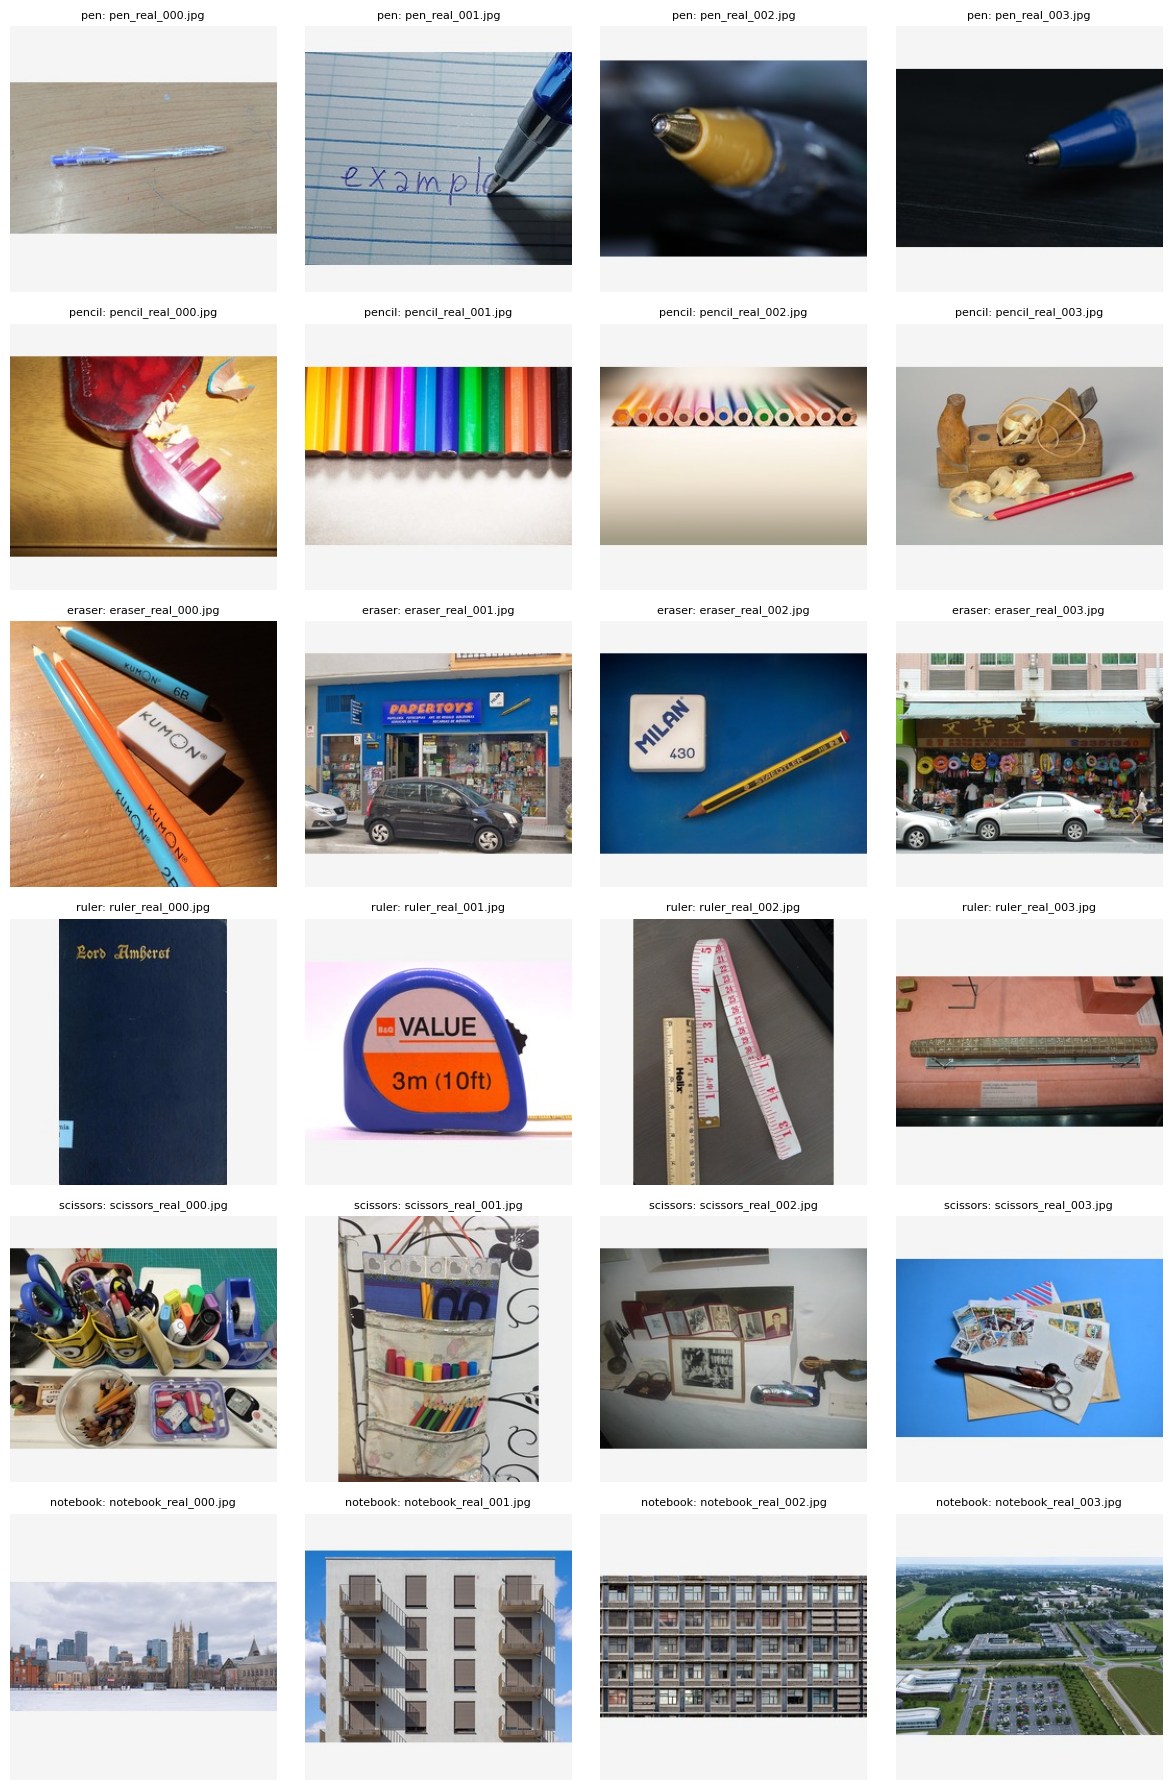

In [6]:
fig, axes = plt.subplots(len(CLASSES), 4, figsize=(12, 3 * len(CLASSES)))
for row, cls in enumerate(CLASSES):
    for col, image_path in enumerate(real_files[cls][:4]):
        image = plt.imread(image_path)
        axes[row, col].imshow(image)
        axes[row, col].set_title(f'{cls}: {image_path.name}', fontsize=8)
        axes[row, col].axis('off')
    for col in range(len(real_files[cls][:4]), 4):
        axes[row, col].axis('off')
plt.tight_layout()
plt.show()

## 6. Chia tập không rò rỉ ảnh gốc

Chia **ảnh thật trước** theo từng lớp. Tất cả ảnh augmentation sinh từ một ảnh gốc chỉ được đưa vào train cùng ảnh gốc đó; validation và test chỉ dùng ảnh thật được giữ riêng. Nhờ vậy, các bản gần giống nhau của cùng một ảnh không xuất hiện ở cả train lẫn test. Với 5 ảnh/lớp, phép chia sẽ là 3 train, 1 validation, 1 test; đây vẫn là đánh giá rất nhỏ.

In [7]:
train_paths, train_labels = [], []
val_paths, val_labels = [], []
test_paths, test_labels = [], []
split_summary = []

for label, cls in enumerate(CLASSES):
    originals = list(real_files[cls])
    random.Random(SEED + label).shuffle(originals)
    n = len(originals)
    n_val = max(1, round(n * 0.2))
    n_test = max(1, round(n * 0.2))
    n_train = n - n_val - n_test
    if n_train < 1:
        raise ValueError(f'Class {cls} needs at least 3 real source images to create train/validation/test splits.')
    train_originals = originals[:n_train]
    val_originals = originals[n_train:n_train + n_val]
    test_originals = originals[n_train + n_val:]
    train_paths.extend(train_originals)
    train_labels.extend([label] * len(train_originals))
    val_paths.extend(val_originals)
    val_labels.extend([label] * len(val_originals))
    test_paths.extend(test_originals)
    test_labels.extend([label] * len(test_originals))

    train_source_ids = {int(re.search(r'_real_(\d+)', p.stem).group(1)) for p in train_originals}
    for augmented_path in aug_files[cls]:
        match = re.search(r'_aug_(\d+)_(\d+)$', augmented_path.stem)
        if match and int(match.group(1)) in train_source_ids:
            train_paths.append(augmented_path)
            train_labels.append(label)
    split_summary.append({'class': cls, 'train_sources': len(train_originals),
                          'validation_sources': len(val_originals), 'test_sources': len(test_originals)})

display(pd.DataFrame(split_summary))
print(f'Train images incl. train-only augmentation: {len(train_paths)}')
print(f'Validation originals: {len(val_paths)} | Test originals: {len(test_paths)}')

,class,train_sources,validation_sources,test_sources
0,pen,3,1,1
1,pencil,3,1,1
2,eraser,3,1,1
3,ruler,3,1,1
4,scissors,3,1,1
5,notebook,3,1,1


Train images incl. train-only augmentation: 378
Validation originals: 6 | Test originals: 6


## 7. Tạo TensorFlow datasets

Ảnh được giải mã thành RGB, resize về 128×128 và nhãn được one-hot encode. `cache` và `prefetch` giúp giảm thời gian chờ khi train.

In [8]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

tf.keras.utils.set_random_seed(SEED)
AUTOTUNE = tf.data.AUTOTUNE
NUM_CLASSES = len(CLASSES)

def decode_resize(path, label):
    image_bytes = tf.io.read_file(path)
    image = tf.io.decode_image(image_bytes, channels=3, expand_animations=False)
    image.set_shape([None, None, 3])
    image = tf.image.resize(image, IMAGE_SIZE)
    image = tf.cast(image, tf.float32) / 255.0
    return image, tf.one_hot(label, NUM_CLASSES)

def make_dataset(paths, labels, training=False):
    if not paths:
        raise ValueError('Cannot create an empty dataset split.')
    dataset = tf.data.Dataset.from_tensor_slices(([str(p) for p in paths], labels))
    if training:
        dataset = dataset.shuffle(len(paths), seed=SEED, reshuffle_each_iteration=True)
    dataset = dataset.map(decode_resize, num_parallel_calls=AUTOTUNE)
    dataset = dataset.cache().batch(BATCH_SIZE).prefetch(AUTOTUNE)
    return dataset

train_ds = make_dataset(train_paths, train_labels, training=True)
val_ds = make_dataset(val_paths, val_labels)
test_ds = make_dataset(test_paths, test_labels)
print('TensorFlow:', tf.__version__)
print('Dataset batches:', len(train_ds), len(val_ds), len(test_ds))

TensorFlow: 2.21.0
Dataset batches: 12 1 1


## 8. Xây dựng và huấn luyện CNN

Mô hình CNN nhỏ dùng convolution, pooling, batch normalization và dropout. Dừng sớm theo validation loss để hạn chế overfitting. Vì số ảnh thật rất ít, xem đây là mô hình thực hành, không phải hệ thống nhận diện đáng tin cậy.

In [ ]:
model = keras.Sequential([
    keras.Input(shape=(*IMAGE_SIZE, 3)),
    layers.Conv2D(32, 3, padding='same', activation='relu'),
    layers.BatchNormalization(),
    layers.MaxPooling2D(),
    layers.Conv2D(64, 3, padding='same', activation='relu'),
    layers.BatchNormalization(),
    layers.MaxPooling2D(),
    layers.Conv2D(128, 3, padding='same', activation='relu'),
    layers.BatchNormalization(),
    layers.MaxPooling2D(),
    layers.GlobalAveragePooling2D(),
    layers.Dropout(0.35),
    layers.Dense(64, activation='relu'),
    layers.Dropout(0.25),
    layers.Dense(NUM_CLASSES, activation='softmax'),
])
model.compile(optimizer=keras.optimizers.Adam(learning_rate=1e-3),
              loss='categorical_crossentropy', metrics=['accuracy'])
model.summary()

callbacks = [
    keras.callbacks.EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True),
    keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=2, min_lr=1e-6),
]
history = model.fit(train_ds, validation_data=val_ds, epochs=30, callbacks=callbacks)

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 128, 128, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128, 128, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64, 64, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 32, 32, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 6)              │           390 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 102,790 (401.52 KB)

 Trainable params: 102,342 (399.77 KB)

 Non-trainable params: 448 (1.75 KB)

Epoch 1/30
12/12 ━━━━━━━━━━━━━━━━━━━━ 38s 3s/step - accuracy: 0.4894 - loss: 1.4113 - val_accuracy: 0.1667 - val_loss: 1.7882 - learning_rate: 0.0010
Epoch 2/30
12/12 ━━━━━━━━━━━━━━━━━━━━ 18s 1s/step - accuracy: 0.6905 - loss: 0.8301 - val_accuracy: 0.3333 - val_loss: 1.7928 - learning_rate: 0.0010
Epoch 3/30
12/12 ━━━━━━━━━━━━━━━━━━━━ 19s 2s/step - accuracy: 0.8333 - loss: 0.4823 - val_accuracy: 0.1667 - val_loss: 1.8119 - learning_rate: 0.0010
Epoch 4/30
12/12 ━━━━━━━━━━━━━━━━━━━━ 21s 2s/step - accuracy: 0.9074 - loss: 0.3742 - val_accuracy: 0.1667 - val_loss: 1.8397 - learning_rate: 5.0000e-04
Epoch 5/30
12/12 ━━━━━━━━━━━━━━━━━━━━ 19s 2s/step - accuracy: 0.9524 - loss: 0.2431 - val_accuracy: 0.1667 - val_loss: 1.8762 - learning_rate: 5.0000e-04
Epoch 6/30
12/12 ━━━━━━━━━━━━━━━━━━━━ 19s 1s/step - accuracy: 0.9630 - loss: 0.2148 - val_accuracy: 0.1667 - val_loss: 1.9295 - learning_rate: 2.5000e-04


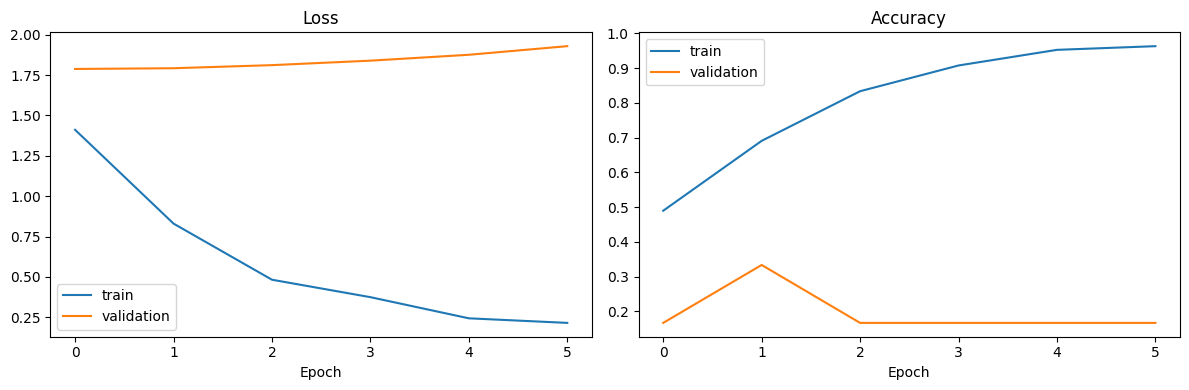

In [ ]:
history_df = pd.DataFrame(history.history)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(history_df['loss'], label='train')
axes[0].plot(history_df['val_loss'], label='validation')
axes[0].set_title('Loss'); axes[0].set_xlabel('Epoch'); axes[0].legend()
axes[1].plot(history_df['accuracy'], label='train')
axes[1].plot(history_df['val_accuracy'], label='validation')
axes[1].set_title('Accuracy'); axes[1].set_xlabel('Epoch'); axes[1].legend()
plt.tight_layout(); plt.show()

## 9. Đánh giá trên test set

Test set gồm ảnh gốc đã giữ lại và không có augmentation. Classification report và confusion matrix giúp nhận ra lớp dễ nhầm; với cấu hình mặc định chỉ có một ảnh test mỗi lớp, nên từng mẫu làm thay đổi accuracy rất mạnh.

Test loss: 1.7867 | Test accuracy: 0.1667
              precision    recall  f1-score   support

         pen       0.00      0.00      0.00         1
      pencil       0.17      1.00      0.29         1
      eraser       0.00      0.00      0.00         1
       ruler       0.00      0.00      0.00         1
    scissors       0.00      0.00      0.00         1
    notebook       0.00      0.00      0.00         1

    accuracy                           0.17         6
   macro avg       0.03      0.17      0.05         6
weighted avg       0.03      0.17      0.05         6



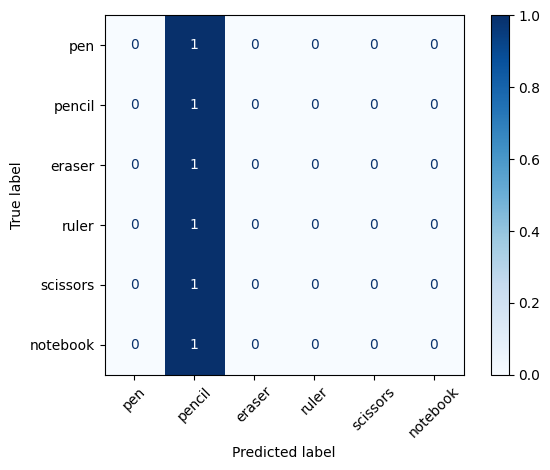

In [ ]:
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

test_loss, test_accuracy = model.evaluate(test_ds, verbose=0)
probabilities = model.predict(test_ds, verbose=0)
y_true = np.asarray(test_labels)
y_pred = probabilities.argmax(axis=1)
print(f'Test loss: {test_loss:.4f} | Test accuracy: {test_accuracy:.4f}')
print(classification_report(y_true, y_pred, labels=range(NUM_CLASSES),
                            target_names=CLASSES, zero_division=0))
matrix = confusion_matrix(y_true, y_pred, labels=range(NUM_CLASSES))
ConfusionMatrixDisplay(matrix, display_labels=CLASSES).plot(cmap='Blues', xticks_rotation=45)
plt.tight_layout(); plt.show()

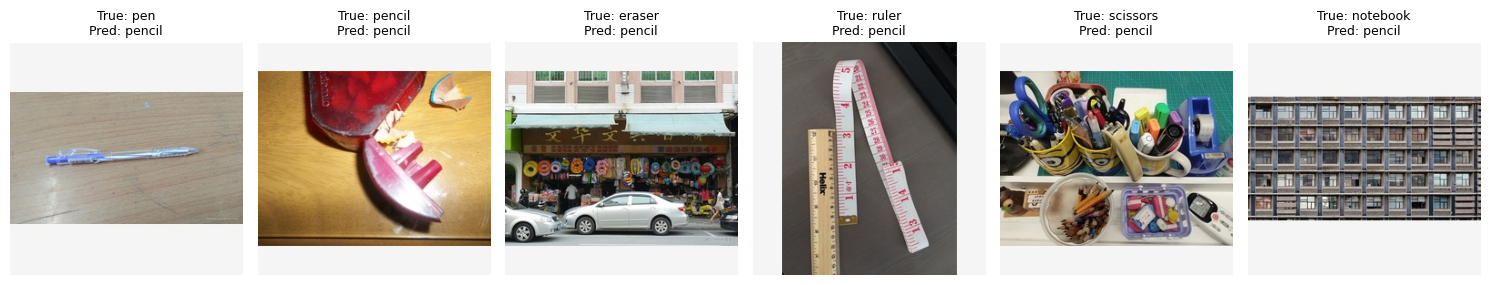

In [ ]:
fig, axes = plt.subplots(1, min(6, len(test_paths)), figsize=(15, 3))
axes = np.atleast_1d(axes)
for i, (path, true_label) in enumerate(zip(test_paths[:6], test_labels[:6])):
    image = plt.imread(path)
    axes[i].imshow(image)
    axes[i].set_title(f'True: {CLASSES[true_label]}\nPred: {CLASSES[y_pred[i]]}', fontsize=9)
    axes[i].axis('off')
plt.tight_layout(); plt.show()

## 10. Lưu mô hình và dự đoán ảnh mới

Tải mô hình `.keras` và danh sách lớp xuống để sử dụng lại. Khi chia sẻ bộ ảnh, giữ `metadata.csv` và cung cấp attribution theo license của từng ảnh.

In [ ]:
MODEL_PATH = Path('/content/smart_school_desk_cnn.keras')
LABELS_PATH = Path('/content/class_names.json')
model.save(MODEL_PATH)
LABELS_PATH.write_text(json.dumps(CLASSES, ensure_ascii=False, indent=2), encoding='utf-8')
print('Saved:', MODEL_PATH, LABELS_PATH)

def predict_image(image_path):
    image = tf.keras.utils.load_img(image_path, target_size=IMAGE_SIZE)
    array = tf.keras.utils.img_to_array(image).astype('float32') / 255.0
    scores = model.predict(array[None, ...], verbose=0)[0]
    best = int(scores.argmax())
    return {'class': CLASSES[best], 'confidence': float(scores[best]),
            'scores': {name: float(score) for name, score in zip(CLASSES, scores)}}

# Ví dụ: print(predict_image('/content/my_school_supply.jpg'))
from google.colab import files
files.download(str(MODEL_PATH))
files.download(str(LABELS_PATH))

Saved: /content/smart_school_desk_cnn.keras /content/class_names.json


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Kết luận và hướng cải thiện

- Thu thập thêm ảnh thật do sinh viên tự chụp với nền, ánh sáng, khoảng cách và góc nhìn khác nhau.
- Giữ nguyên tách biệt nguồn ảnh giữa train/validation/test; chỉ augment train.
- Đánh giá trên test set đủ lớn, độc lập và có nhiều mẫu mỗi lớp trước khi đưa mô hình vào sử dụng.
- Kiểm tra metadata/giấy phép và lưu attribution khi tái sử dụng ảnh.
- Thử transfer learning sau khi đã có dataset đa dạng hơn; không kết luận chất lượng mô hình chỉ từ accuracy của starter dataset.